# Track C - Prediction-driven Inventory Replenishment Optimisation

This notebook forecasts demand and uses a constrained MILP to decide replenishment quantities for 50 SKUs across 5 warehouses.

It compares the optimizer with the existing rule and a greedy policy using cost, service level, inventory and capacity results.

In [31]:
import random, re, time, warnings, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm as lgb
import pulp
import shap
import mlflow
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import norm

warnings.filterwarnings('ignore')
logging.getLogger('mlflow').setLevel(logging.ERROR)
logging.getLogger('alembic').setLevel(logging.ERROR)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

RAW_PATH = Path('supply_chain_dataset1.csv')
ENRICHED_PATH = Path('supply_chain_dataset1_enriched.csv')
RESULTS_DIR = Path('results'); RESULTS_DIR.mkdir(exist_ok=True)

TRAIN_END = pd.Timestamp('2024-08-31')   # forecaster training targets end here
VAL_END = pd.Timestamp('2024-09-30')     # model selection + parameter calibration end here
EVAL_START = pd.Timestamp('2024-10-01')  # out-of-sample optimisation starts here
H = 28                                   # planning horizon (days)
REPLAN = 14                              # re-plan cadence; only the first 14 days of each plan are executed
EVAL_DAYS = 84                           # rolling evaluation Oct 1 -> Dec 23
MILP_TL = 45                             # CBC time limit per MILP solve (s)
SERVICE_Z = norm.ppf(0.95)               # 95% cycle service level for safety stock

mlflow.set_tracking_uri('sqlite:///' + Path('mlflow.db').resolve().as_posix())
mlflow.set_experiment('trackC_prediction_driven_replenishment')


def mlflow_clean(metrics):
    return {re.sub(r'[^0-9A-Za-z_\-. /]', '', k.replace('%', 'pct')).strip(): float(v) for k, v in metrics.items()}


for lib in [pd, np, sklearn, lgb, pulp, shap, mlflow]:
    print(f'{lib.__name__:<10} {lib.__version__}')


pandas     3.0.6
numpy      2.4.6
sklearn    1.9.1
lightgbm   4.7.0
pulp       3.3.2
shap       0.51.0
mlflow     3.16.1


## 1. Data ingestion and EDA

Load the daily supply-chain data and check its quality before modelling.

In [2]:
raw = pd.read_csv(RAW_PATH, parse_dates=['Date'])
raw = raw.sort_values(['SKU_ID', 'Warehouse_ID', 'Date']).reset_index(drop=True)
raw['pair'] = raw['SKU_ID'] + '|' + raw['Warehouse_ID']

print('Shape:', raw.shape, '| dates:', raw.Date.min().date(), '->', raw.Date.max().date())
print('SKU x warehouse pairs:', raw.pair.nunique(), '| rows per pair:', raw.groupby('pair').size().unique())
print('Missing values:', int(raw.isna().sum().sum()))
static_cols = ['Supplier_ID', 'Supplier_Lead_Time_Days', 'Reorder_Point', 'Unit_Cost', 'Unit_Price', 'Region']
display(pd.Series({c: raw.groupby('pair')[c].nunique().max() for c in static_cols},
                  name='max distinct values per SKU-warehouse pair').to_frame())
display(raw.describe().T.round(2))

Shape: (91250, 16) | dates: 2024-01-01 -> 2024-12-30
SKU x warehouse pairs: 250 | rows per pair: [365]
Missing values: 0


,max distinct values per SKU-warehouse pair
Supplier_ID,1
Supplier_Lead_Time_Days,1
Reorder_Point,1
Unit_Cost,1
Unit_Price,1
Region,4


,count,mean,min,25%,50%,75%,max,std
Date,91250,2024-07-01 00:00:00,2024-01-01 00:00:00,2024-04-01 00:00:00,2024-07-01 00:00:00,2024-09-30 00:00:00,2024-12-30 00:00:00,NaN
Units_Sold,91250.0,20.054564,0.0,13.0,20.0,27.0,59.0,9.068602
Inventory_Level,91250.0,471.522312,168.0,370.0,461.0,564.0,990.0,133.488002
Supplier_Lead_Time_Days,91250.0,7.984,2.0,4.0,8.0,11.0,14.0,3.907929
Reorder_Point,91250.0,300.068,201.0,252.0,300.0,346.0,398.0,54.879945
Order_Quantity,91250.0,19.272493,0.0,0.0,0.0,0.0,499.0,82.340831
Unit_Cost,91250.0,12.20332,5.02,8.18,11.99,16.32,19.76,4.574982
Unit_Price,91250.0,18.2618,6.95,12.0,18.18,23.39,35.1,7.121136
Promotion_Flag,91250.0,0.101589,0.0,0.0,0.0,0.0,1.0,0.302109
Stockout_Flag,91250.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


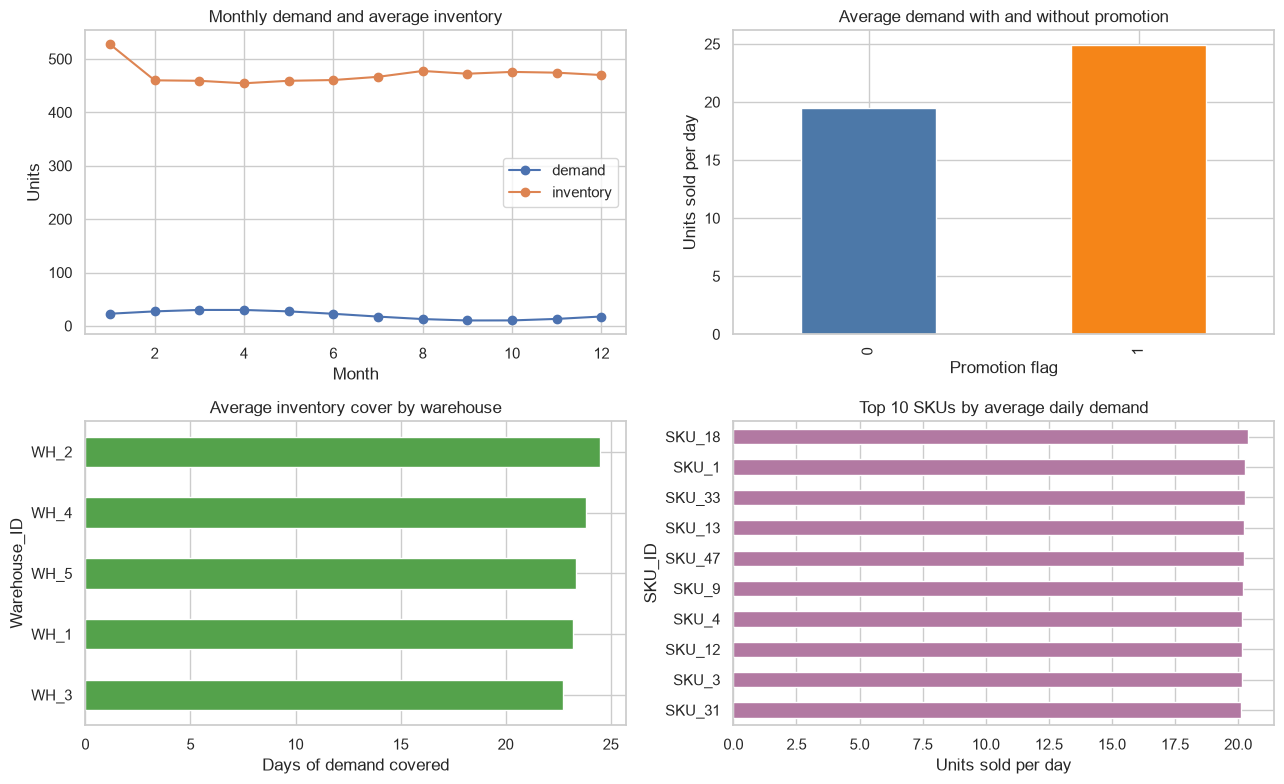

Peak monthly demand: month 3 (29.9 units per pair/day)
Promotion lift: 27.7%
Warehouse cover range: 22.7-24.5 days


In [41]:
monthly = raw.groupby(raw.Date.dt.month).agg(
    demand=('Units_Sold', 'mean'),
    inventory=('Inventory_Level', 'mean')
)
promo = raw.groupby('Promotion_Flag').Units_Sold.mean()
warehouse = raw.groupby('Warehouse_ID').agg(
    average_inventory=('Inventory_Level', 'mean'),
    average_demand=('Units_Sold', 'mean')
)
warehouse['days_of_cover'] = warehouse.average_inventory / warehouse.average_demand
sku_demand = raw.groupby('SKU_ID').Units_Sold.mean().sort_values(ascending=False).head(10)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
monthly[['demand', 'inventory']].plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('Monthly demand and average inventory')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Units')

promo.plot.bar(ax=axes[0, 1], color=['#4C78A8', '#F58518'])
axes[0, 1].set_title('Average demand with and without promotion')
axes[0, 1].set_xlabel('Promotion flag')
axes[0, 1].set_ylabel('Units sold per day')

warehouse.days_of_cover.sort_values().plot.barh(ax=axes[1, 0], color='#54A24B')
axes[1, 0].set_title('Average inventory cover by warehouse')
axes[1, 0].set_xlabel('Days of demand covered')

sku_demand.sort_values().plot.barh(ax=axes[1, 1], color='#B279A2')
axes[1, 1].set_title('Top 10 SKUs by average daily demand')
axes[1, 1].set_xlabel('Units sold per day')

plt.tight_layout()
plt.show()

print(f'Peak monthly demand: month {monthly.demand.idxmax()} ({monthly.demand.max():.1f} units per pair/day)')
print(f'Promotion lift: {100 * (promo.loc[1] / promo.loc[0] - 1):.1f}%')
print(f'Warehouse cover range: {warehouse.days_of_cover.min():.1f}-{warehouse.days_of_cover.max():.1f} days')

### Quick business view

A few charts show demand seasonality, promotions, inventory cover and high-demand SKUs.

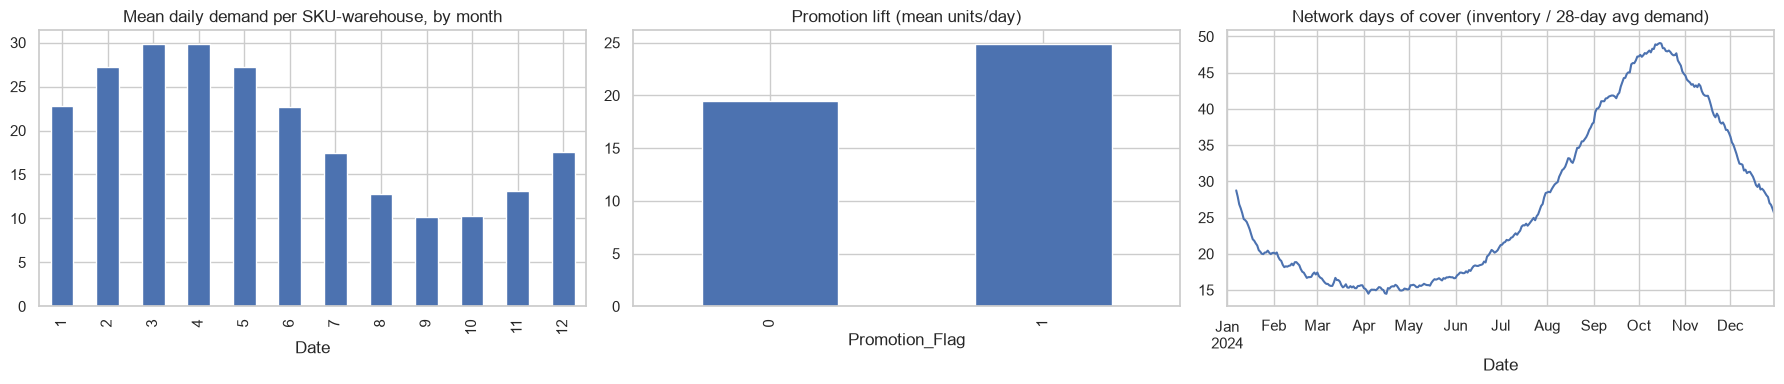

Inventory change explained by a SAME-DAY receipt of Order_Quantity: 100.0%
Stockout_Flag positive rows: 0
Orders placed on 5.5% of pair-days, size 200-499 units
Average days of cover held: 27.2

MAE of provided Demand_Forecast                       : 2.38
MAE of in-sample oracle (pair x month x promo mean)    : 4.03
Corr(forecast - level, actual - level)                 : 0.86


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
raw.groupby(raw.Date.dt.month).Units_Sold.mean().plot.bar(ax=axes[0], title='Mean daily demand per SKU-warehouse, by month')
raw.groupby('Promotion_Flag').Units_Sold.mean().plot.bar(ax=axes[1], title='Promotion lift (mean units/day)')
net = raw.groupby('Date')[['Units_Sold', 'Inventory_Level']].sum()
(net.Inventory_Level / net.Units_Sold.rolling(28, min_periods=7).mean()).plot(
    ax=axes[2], title='Network days of cover (inventory / 28-day avg demand)')
plt.tight_layout(); plt.show()

by_pair = raw.groupby('pair')
inv_change = raw.Inventory_Level - by_pair.Inventory_Level.shift(1) + raw.Units_Sold
has_prev = by_pair.cumcount() > 0
orders_hist = raw.loc[raw.Order_Quantity > 0, 'Order_Quantity']
print(f'Inventory change explained by a SAME-DAY receipt of Order_Quantity: {(inv_change == raw.Order_Quantity)[has_prev].mean():.1%}')
print(f'Stockout_Flag positive rows: {int(raw.Stockout_Flag.sum())}')
print(f'Orders placed on {(raw.Order_Quantity > 0).mean():.1%} of pair-days, size {orders_hist.min()}-{orders_hist.max()} units')
print(f'Average days of cover held: {(net.Inventory_Level / net.Units_Sold.rolling(28, min_periods=7).mean()).mean():.1f}')

# Leakage test: can the provided forecast beat an in-sample oracle that knows each pair's monthly/promo mean?
level = raw.groupby(['pair', raw.Date.dt.month, 'Promotion_Flag']).Units_Sold.transform('mean')
print(f'\nMAE of provided Demand_Forecast                       : {np.abs(raw.Demand_Forecast - raw.Units_Sold).mean():.2f}')
print(f'MAE of in-sample oracle (pair x month x promo mean)    : {np.abs(level - raw.Units_Sold).mean():.2f}')
print(f'Corr(forecast - level, actual - level)                 : '
      f'{np.corrcoef(raw.Demand_Forecast - level, raw.Units_Sold - level)[0, 1]:.2f}')

The data shows clear seasonality and high inventory cover. Supplier, lead-time and cost fields are stable by SKU-warehouse pair, while the supplied forecast is excluded because it appears to use future information.

## 2. Dataset enrichment

The source data does not include all business costs and capacity limits, so reasonable assumptions are added to the same dataset for the optimization model.

In [5]:
df = raw.copy()
calib = df.Date <= VAL_END
rng = np.random.default_rng(SEED)

suppliers = sorted(df.Supplier_ID.unique())
order_cost = dict(zip(suppliers, rng.integers(60, 121, len(suppliers)).astype(float)))
sup_daily = df[calib].groupby(['Supplier_ID', 'Date']).Units_Sold.sum().groupby('Supplier_ID').mean()
wh_daily = df[calib].groupby(['Warehouse_ID', 'Date']).Units_Sold.sum().groupby('Warehouse_ID').mean()
wh_peak_stock = df[calib].groupby(['Warehouse_ID', 'Date']).Inventory_Level.sum().groupby('Warehouse_ID').max()

df['Holding_Cost_Per_Unit_Day'] = (0.25 * df.Unit_Cost / 365).round(5)
df['Order_Fixed_Cost'] = df.Supplier_ID.map(order_cost)
df['Stockout_Penalty_Per_Unit'] = ((df.Unit_Price - df.Unit_Cost) + 0.25 * df.Unit_Price).round(2)
df['MOQ'] = int(orders_hist.min())
df['Max_Order_Qty'] = int(np.ceil(orders_hist.max() / 100) * 100)
df['Supplier_Daily_Capacity'] = df.Supplier_ID.map((1.5 * sup_daily).round())
df['Warehouse_Receiving_Capacity'] = df.Warehouse_ID.map(wh_daily.round())
df['Warehouse_Storage_Capacity'] = df.Warehouse_ID.map(wh_peak_stock)

NEW_COLS = ['Holding_Cost_Per_Unit_Day', 'Order_Fixed_Cost', 'Stockout_Penalty_Per_Unit', 'MOQ', 'Max_Order_Qty',
            'Supplier_Daily_Capacity', 'Warehouse_Receiving_Capacity', 'Warehouse_Storage_Capacity']
df.drop(columns='pair').to_csv(ENRICHED_PATH, index=False)
print(f'Saved {ENRICHED_PATH} with {len(NEW_COLS)} new columns -> shape {df.drop(columns="pair").shape}')
display(df[NEW_COLS].describe().T[['min', 'mean', 'max']].round(3))


Saved supply_chain_dataset1_enriched.csv with 8 new columns -> shape (91250, 23)


,min,mean,max
Holding_Cost_Per_Unit_Day,0.003,0.008,0.014
Order_Fixed_Cost,65.000,87.244,112.000
Stockout_Penalty_Per_Unit,2.970,10.624,24.120
MOQ,200.000,200.000,200.000
Max_Order_Qty,500.000,500.000,500.000
Supplier_Daily_Capacity,533.000,861.204,1134.000
Warehouse_Receiving_Capacity,1107.000,1109.600,1113.000
Warehouse_Storage_Capacity,34889.000,36065.800,36959.000


## 3. Stage 1 - Demand forecasting

Compare two forecasting models with moving-average baselines, then pass the selected forecast to the optimizer.

In [6]:
D = df.pivot(index='Date', columns='pair', values='Units_Sold')
PROMO = df.pivot(index='Date', columns='pair', values='Promotion_Flag')
DATES, PAIRS = D.index, list(D.columns)
N = len(PAIRS)
meta = df.drop_duplicates('pair').set_index('pair').loc[PAIRS]
meta['sku'] = meta.SKU_ID.str.split('_').str[1].astype(int)
meta['wh'] = meta.Warehouse_ID.str.split('_').str[1].astype(int)
LEAD = meta.Supplier_Lead_Time_Days.to_numpy(int)
FEATS = ['lag1', 'mean7', 'mean7_prev', 'trend7', 'mean28', 'std28', 'mean56', 'promo_rate28',
         'h', 'promo', 'dow', 'sku', 'wh', 'lead']


def make_features(origin, horizon=H):
    """Rows (pair, h) for forecasts issued at the end of `origin`, using history up to and including `origin`."""
    i = DATES.get_loc(origin)
    hist = D.iloc[:i + 1]
    base = pd.DataFrame({
        'lag1': hist.iloc[-1], 'mean7': hist.iloc[-7:].mean(), 'mean7_prev': hist.iloc[-14:-7].mean(),
        'mean28': hist.iloc[-28:].mean(), 'std28': hist.iloc[-28:].std(), 'mean56': hist.iloc[-56:].mean(),
        'promo_rate28': PROMO.iloc[i - 27:i + 1].mean(),
    })
    base['trend7'] = base.mean7 - base.mean7_prev
    base['sku'], base['wh'], base['lead'] = meta.sku, meta.wh, LEAD
    frames = []
    for h in range(1, horizon + 1):
        date = origin + pd.Timedelta(days=h)
        known = i + h < len(DATES)
        f = base.copy()
        f['h'], f['dow'], f['origin'], f['date'] = h, date.dayofweek, origin, date
        f['promo'] = PROMO.iloc[i + h].to_numpy() if known else 0
        f['y'] = D.iloc[i + h].to_numpy() if known else np.nan
        frames.append(f.rename_axis('pair').reset_index())
    return pd.concat(frames, ignore_index=True)


t0 = time.time()
panel = pd.concat([make_features(o) for o in DATES[55::7]], ignore_index=True)
panel = panel[panel.y.notna()].reset_index(drop=True)
print(f'Training panel: {panel.shape[0]:,} rows from {panel.origin.nunique()} weekly origins ({time.time() - t0:.1f}s)')


Training panel: 298,500 rows from 45 weekly origins (4.1s)


Train rows 177,500 | validation rows 19,000 | selected forecaster: RandomForest
Irreducible MAE if demand were Poisson(mean=10.0): 2.51


,MAE,RMSE,WAPE %,Bias (pred - actual),fit time s
Naive MA-7,4.369,5.409,43.479,0.656,NaN
Naive MA-28,4.420,5.454,43.989,1.724,NaN
LightGBM-Poisson,4.188,5.192,41.679,1.038,3.052
RandomForest,4.117,5.106,40.971,0.780,6.730


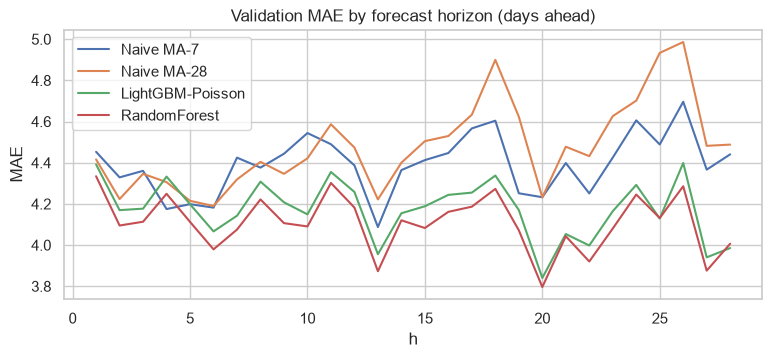

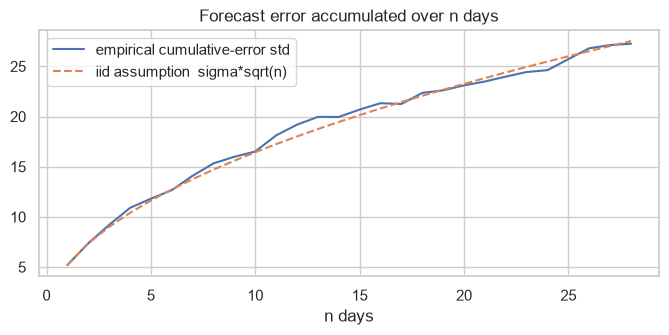

Cumulative-error std at 14/21/28 days: 20.0 / 23.5 / 27.3 units vs iid assumption 19.5 / 23.8 / 27.5


In [32]:
MODELS = {
    'LightGBM-Poisson': lambda: lgb.LGBMRegressor(
        objective='poisson', n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
    'RandomForest': lambda: RandomForestRegressor(
        n_estimators=150, max_depth=12, min_samples_leaf=20, max_samples=0.5, n_jobs=-1, random_state=SEED),
}


def fit_model(name, train):
    model = MODELS[name]()
    if name.startswith('LightGBM'):
        model.fit(train[FEATS], train.y, categorical_feature=['sku', 'wh'])
    else:
        model.fit(train[FEATS], train.y)
    return model


def score(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': np.sqrt(mean_squared_error(y, p)),
            'WAPE %': 100 * np.abs(y - p).sum() / y.sum(), 'Bias (pred - actual)': float(np.mean(p - y))}


train = panel[panel.date <= TRAIN_END]
val = pd.concat([make_features(o) for o in pd.date_range(TRAIN_END, VAL_END - pd.Timedelta(days=7), freq='7D')])
val = val[val.date <= VAL_END].reset_index(drop=True)

val_pred = {'Naive MA-7': val.mean7.to_numpy(), 'Naive MA-28': val.mean28.to_numpy()}
fitted, fit_time = {}, {}
for name in MODELS:
    t0 = time.time()
    fitted[name] = fit_model(name, train)
    fit_time[name] = time.time() - t0
    val_pred[name] = np.clip(fitted[name].predict(val[FEATS]), 0, None)

val_scores = pd.DataFrame({k: score(val.y.to_numpy(), p) for k, p in val_pred.items()}).T
val_scores['fit time s'] = pd.Series(fit_time)
BEST = min(MODELS, key=lambda n: val_scores.loc[n, 'MAE'])
lam = val.y.mean()
poisson_floor = sum(abs(k - lam) * np.exp(-lam + k * np.log(lam) - np.sum(np.log(np.arange(1, k + 1)))) for k in range(150))
print(f'Train rows {len(train):,} | validation rows {len(val):,} | selected forecaster: {BEST}')
print(f'Irreducible MAE if demand were Poisson(mean={lam:.1f}): {poisson_floor:.2f}')
display(val_scores.round(3))

err_h = pd.DataFrame({k: np.abs(val.y - p) for k, p in val_pred.items()}).groupby(val.h).mean()
err_h.plot(figsize=(9, 3.5), title='Validation MAE by forecast horizon (days ahead)', ylabel='MAE'); plt.show()

# Safety stock inputs. Plans are frozen for REPLAN days, so the buffer must cover forecast error over lead time + review
# period. Daily errors are autocorrelated, so the spread of the *cumulative* error is measured directly (not sigma*sqrt(n)).
first = val[val.origin == TRAIN_END].sort_values(['pair', 'h']).copy()
first['err'] = first.y - val_pred[BEST][first.index]
first['cum_err'] = first.groupby('pair').err.cumsum()
first['cum_fc'] = pd.Series(val_pred[BEST][first.index], index=first.index).groupby(first.pair).cumsum()
cum = first.groupby('h').agg(sd_cum=('cum_err', 'std'), mean_cum_fc=('cum_fc', 'mean'))
REL_SIGMA = (cum.sd_cum / cum.mean_cum_fc).to_dict()          # cumulative error spread relative to forecast volume
iid = first.groupby('h').err.std().iloc[0] * np.sqrt(cum.index)
ax = cum.sd_cum.plot(figsize=(8, 3.2), label='empirical cumulative-error std', title='Forecast error accumulated over n days')
ax.plot(cum.index, iid, '--', label='iid assumption  sigma*sqrt(n)'); ax.set_xlabel('n days'); ax.legend(); plt.show()
print(f'Cumulative-error std at 14/21/28 days: {cum.sd_cum.loc[14]:.1f} / {cum.sd_cum.loc[21]:.1f} / {cum.sd_cum.loc[28]:.1f} units '
      f'vs iid assumption {iid[13]:.1f} / {iid[20]:.1f} / {iid[27]:.1f}')


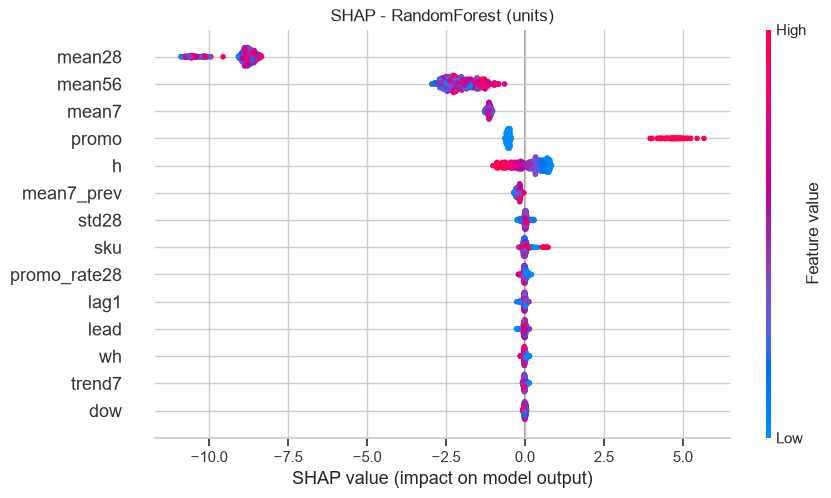

,mean28,mean56,mean7,promo,h,mean7_prev,std28,sku,promo_rate28,lag1,lead,wh,trend7,dow
mean |SHAP|,8.937,2.032,1.14,1.013,0.46,0.201,0.049,0.049,0.034,0.028,0.027,0.026,0.022,0.017


In [33]:
# SHAP explanation of the selected forecaster (validation sample)
sample = val.sample(500, random_state=SEED)[FEATS]
shap_values = shap.TreeExplainer(fitted[BEST]).shap_values(sample)
shap.summary_plot(shap_values, sample, show=False, plot_size=(9, 5))
plt.title(f'SHAP - {BEST}' + (' (log-demand scale)' if BEST.startswith('LightGBM') else ' (units)'))
plt.show()
shap_rank = pd.Series(np.abs(shap_values).mean(0), index=FEATS).sort_values(ascending=False)
display(shap_rank.round(3).to_frame('mean |SHAP|').T)


### Held-out test

Models are retrained at each planning date and tested on the next 28 days. A small recent-demand correction is used to handle the Q4 rise.

In [34]:
BLOCKS = list(range(0, EVAL_DAYS, REPLAN))
EVAL_DATES = pd.date_range(EVAL_START, periods=EVAL_DAYS)
RAW_FC = {name: {} for name in MODELS}
ROWS = {}
t0 = time.time()
for d in BLOCKS:
    origin = EVAL_START + pd.Timedelta(days=d - 1)
    ROWS[d] = make_features(origin)
    tr = panel[panel.date <= origin]
    for name in MODELS:
        pred = np.clip(fit_model(name, tr).predict(ROWS[d][FEATS]), 0, None)
        RAW_FC[name][d] = ROWS[d].assign(pred=pred).pivot(index='pair', columns='h', values='pred').loc[PAIRS].to_numpy()
print(f'{len(BLOCKS)} origins x {len(MODELS)} models retrained in {time.time() - t0:.0f}s')


def level_corrected(raw_fc, val_p):
    """Scale each plan's forecast by actual/forecast over the 14 days before its origin (already observed)."""
    last = val.origin == val.origin.max()
    ratios, out = {}, {}
    for d in BLOCKS:
        if d == 0:
            act, fc = val.y[last].sum(), val_p[last.to_numpy()].sum()
        else:
            act, fc = ACTUAL_ALL[:, d - REPLAN:d].sum(), raw_fc[d - REPLAN][:, :REPLAN].sum()
        ratios[d] = float(np.clip(act / fc, 0.7, 1.5))
        out[d] = raw_fc[d] * ratios[d]
    return out, ratios


ACTUAL_ALL = D.loc[EVAL_START:, PAIRS].T.to_numpy(float)   # Oct 1 -> Dec 30, used only after it is observed
FORECASTS, RATIOS = {}, {}
for name in MODELS:
    FORECASTS[name], RATIOS[name] = level_corrected(RAW_FC[name], val_pred[name])


def eval_fc(fc):
    p, a = [], []
    for d in BLOCKS:
        n = min(H, ACTUAL_ALL.shape[1] - d)
        p.append(fc[d][:, :n].ravel()); a.append(ACTUAL_ALL[:, d:d + n].ravel())
    return score(np.concatenate(a), np.concatenate(p))


naive = {k: {d: np.repeat(ROWS[d].groupby('pair')[k].first().loc[PAIRS].to_numpy()[:, None], H, 1) for d in BLOCKS}
         for k in ['mean7', 'mean28']}
test_scores = pd.DataFrame({
    'Naive MA-7': eval_fc(naive['mean7']), 'Naive MA-28': eval_fc(naive['mean28']),
    **{f'{n} (raw)': eval_fc(RAW_FC[n]) for n in MODELS},
    **{f'{n} + level correction': eval_fc(FORECASTS[n]) for n in MODELS},
}).T
display(test_scores.round(3))
print('Level-correction factors applied per plan:', {d: round(r, 2) for d, r in RATIOS[BEST].items()})
FC = FORECASTS[BEST]

with mlflow.start_run(run_name='stage1_forecasting'):
    mlflow.log_params({'selected_model': BEST, 'horizon': H, 'train_end': str(TRAIN_END.date()),
                       'features': ','.join(FEATS), 'service_z': round(SERVICE_Z, 3), 'level_correction': 'prev 14d, clip 0.7-1.5'})
    mlflow.log_metrics(mlflow_clean({f'val {m} {k}': v for m in val_scores.index for k, v in val_scores.loc[m].dropna().items()}))
    mlflow.log_metrics(mlflow_clean({f'test {m} {k}': v for m in test_scores.index for k, v in test_scores.loc[m].items()}))


6 origins x 2 models retrained in 78s


,MAE,RMSE,WAPE %,Bias (pred - actual)
Naive MA-7,4.720,5.966,34.524,-1.700
Naive MA-28,4.843,6.119,35.421,-2.422
LightGBM-Poisson (raw),4.884,6.139,35.723,-2.582
RandomForest (raw),4.786,6.024,35.003,-2.411
LightGBM-Poisson + level correction,4.442,5.577,32.488,-1.508
RandomForest + level correction,4.415,5.544,32.291,-1.324


Level-correction factors applied per plan: {0: 0.91, 14: 0.99, 28: 1.05, 42: 1.15, 56: 1.19, 70: 1.25}


## 4. Stage 2 - Optimisation formulation

The MILP chooses order quantities while accounting for lead time, MOQ, supplier capacity, warehouse capacity, holding cost and lost-sales cost. An LP relaxation and practical baselines are also compared.

In [35]:
MOQ, MAXQ = int(meta.MOQ.iloc[0]), int(meta.Max_Order_Qty.iloc[0])
SUP_OF, WH_OF = meta.Supplier_ID.to_numpy(), meta.Warehouse_ID.to_numpy()
SUP_COUNT, WH_COUNT = meta.Supplier_ID.value_counts(), meta.Warehouse_ID.value_counts()
DOCK_PENALTY = 1e4
H_COST = meta.Holding_Cost_Per_Unit_Day.to_numpy()
PEN = meta.Stockout_Penalty_Per_Unit.to_numpy()
# Newsvendor critical ratio per pair: a unit short costs PEN, a unit too many is held for ~one review period
CRIT_RATIO = PEN / (PEN + H_COST * REPLAN)
Z_P = norm.ppf(np.minimum(CRIT_RATIO, 0.99))


def fc_sum(F, k, n):
    """Forecast demand over the next n[p] days starting k days into the plan; the tail beyond H uses the last week's mean."""
    return np.array([F[p, k:k + n[p]].sum() + max(0, k + n[p] - H) * F[p, -7:].mean() for p in range(N)])


def compute_ss(F, lead=LEAD):
    """Safety stock for one plan: z(critical ratio) x cumulative-error spread over lead time + review period."""
    n = np.minimum(np.asarray(lead) + REPLAN, H)
    return np.ceil(Z_P * np.array([REL_SIGMA[x] for x in n]) * fc_sum(F, 0, n))


BASE = dict(
    h=H_COST, K=meta.Order_Fixed_Cost.to_numpy(), pen=PEN, ss=compute_ss(FC[0]), ss_pen=0.1 * PEN,
    lead=LEAD, moq=MOQ, maxq=MAXQ,
    sup_cap=meta.groupby('Supplier_ID').Supplier_Daily_Capacity.first().to_dict(),
    dock_cap=meta.groupby('Warehouse_ID').Warehouse_Receiving_Capacity.first().to_dict(),
    storage=meta.groupby('Warehouse_ID').Warehouse_Storage_Capacity.first().to_dict(),
)
print(f'Critical ratio {CRIT_RATIO.min():.3f}-{CRIT_RATIO.max():.3f} -> z capped at {Z_P.max():.2f}; '
      f'safety stock for the first plan: mean {BASE["ss"].mean():.0f} units (range {BASE["ss"].min():.0f}-{BASE["ss"].max():.0f})')


def greedy_orders(d, k, F, ip, arrivals, prm=BASE):
    """Capacity-aware greedy: most urgent pairs (fewest days of cover) order up to lead-time + review demand + SS."""
    lead = np.asarray(prm['lead'], int)
    reorder = ip <= fc_sum(F, k, lead) + prm['ss']
    target = fc_sum(F, k, lead + REPLAN) + prm['ss']
    order, sup_used = np.zeros(N), dict.fromkeys(prm['sup_cap'], 0.0)
    for p in np.argsort(ip / (F.mean(axis=1) + 1e-6)):
        if not reorder[p]:
            continue
        sp, w = SUP_OF[p], WH_OF[p]
        dock_used = arrivals[WH_OF == w, d + lead[p]].sum() + order[(WH_OF == w) & (lead == lead[p])].sum()
        room = min(prm['sup_cap'][sp] - sup_used[sp], prm['dock_cap'][w] - dock_used)
        qty = min(float(np.clip(np.round(target[p] - ip[p]), MOQ, MAXQ)), np.floor(room))
        if qty >= MOQ:
            order[p] = qty
            sup_used[sp] += qty
    return order


def greedy_plan(F, inv0, pipe, prm=None):
    """Run the greedy rule on forecast demand inside the plan horizon -> a feasible MILP warm start."""
    prm = {**BASE, **(prm or {})}
    lead = np.asarray(prm['lead'], int)
    arrivals = np.zeros((N, 2 * H + 20)); arrivals[:, :H] = pipe
    inv = inv0.astype(float).copy()
    Q, I, U = np.zeros((N, H)), np.zeros((N, H)), np.zeros((N, H))
    for t in range(H):
        order = greedy_orders(t, t, F, inv + arrivals[:, t:].sum(1), arrivals, prm)
        order[t + lead >= H] = 0
        Q[:, t] = order
        arrivals[np.arange(N), t + lead] += order
        inv = inv + arrivals[:, t] - F[:, t]
        U[:, t] = np.maximum(-inv, 0)
        I[:, t] = inv = np.maximum(inv, 0)
    dock = pd.DataFrame(arrivals[:, :H]).groupby(WH_OF).sum()
    E = {(w, t): max(0.0, dock.loc[w, t] - prm['dock_cap'][w]) for w in dock.index for t in range(H)}
    S = np.maximum(prm['ss'][:, None] - I, 0)
    obj = ((prm['h'][:, None] * I).sum() + (prm['K'][:, None] * (Q > 0)).sum() + (prm['pen'][:, None] * U).sum()
           + (prm['ss_pen'][:, None] * S).sum() + DOCK_PENALTY * sum(E.values()))
    return dict(Q=Q, I=I, U=U, S=S, E=E, obj=obj)


def solve_plan(demand, I0, pipe, mode='milp', prm=None, sel=None, fixed_y=None, warm=None, time_limit=MILP_TL):
    """mode: 'milp' (exact), 'lp' (relaxation), 'fixed' (LP with binaries fixed -> duals). warm: greedy_plan() output."""
    prm = {**BASE, **(prm or {})}
    sel = list(range(N)) if sel is None else [int(p) for p in sel]
    lead = [int(x) for x in prm['lead']]
    t_build = time.time()
    m = pulp.LpProblem('replenishment', pulp.LpMinimize)
    q, y, I, u, S, E, obj = {}, {}, {}, {}, {}, {}, []
    for p in sel:
        for t in range(H):
            I[p, t] = pulp.LpVariable(f'I_{p}_{t}', 0)
            u[p, t] = pulp.LpVariable(f'u_{p}_{t}', 0, float(demand[p, t]))
            S[p, t] = pulp.LpVariable(f's_{p}_{t}', 0)
            if t + lead[p] < H:
                q[p, t] = pulp.LpVariable(f'q_{p}_{t}', 0, prm['maxq'])
                if mode == 'milp':
                    y[p, t] = pulp.LpVariable(f'y_{p}_{t}', cat=pulp.LpBinary)
                elif mode == 'fixed':
                    v = float(fixed_y.get((p, t), 0))
                    y[p, t] = pulp.LpVariable(f'y_{p}_{t}', v, v)
                else:
                    y[p, t] = pulp.LpVariable(f'y_{p}_{t}', 0, 1)
                m += q[p, t] >= prm['moq'] * y[p, t], f'moq_{p}_{t}'
                m += q[p, t] <= prm['maxq'] * y[p, t], f'maxq_{p}_{t}'
                obj.append(prm['K'][p] * y[p, t])
            prev = I[p, t - 1] if t else float(I0[p])
            m += I[p, t] == prev + q.get((p, t - lead[p]), 0) + float(pipe[p, t]) - float(demand[p, t]) + u[p, t], f'bal_{p}_{t}'
            m += I[p, t] + S[p, t] >= float(prm['ss'][p]), f'ss_{p}_{t}'
            obj += [prm['h'][p] * I[p, t], prm['pen'][p] * u[p, t], prm['ss_pen'][p] * S[p, t]]
    for sp in sorted({SUP_OF[p] for p in sel}):
        ps = [p for p in sel if SUP_OF[p] == sp]
        cap = prm['sup_cap'][sp] * len(ps) / SUP_COUNT[sp]
        for t in range(H):
            terms = [q[p, t] for p in ps if (p, t) in q]
            if terms:
                m += pulp.lpSum(terms) <= cap, f'sup_{sp}_{t}'
    for w in sorted({WH_OF[p] for p in sel}):
        ps = [p for p in sel if WH_OF[p] == w]
        share = len(ps) / WH_COUNT[w]
        for t in range(H):
            E[w, t] = pulp.LpVariable(f'e_{w}_{t}', 0)
            arriving = [q[p, t - lead[p]] for p in ps if (p, t - lead[p]) in q]
            m += pulp.lpSum(arriving) + float(pipe[ps, t].sum()) <= prm['dock_cap'][w] * share + E[w, t], f'dock_{w}_{t}'
            m += pulp.lpSum(I[p, t] for p in ps) <= prm['storage'][w] * share, f'store_{w}_{t}'
            obj.append(DOCK_PENALTY * E[w, t])
    m += pulp.lpSum(obj)
    if warm is not None:
        for (p, t), v in q.items():
            v.setInitialValue(warm['Q'][p, t]); y[p, t].setInitialValue(int(warm['Q'][p, t] > 0))
        for (p, t), v in I.items():
            v.setInitialValue(warm['I'][p, t]); u[p, t].setInitialValue(warm['U'][p, t]); S[p, t].setInitialValue(warm['S'][p, t])
        for k, v in E.items():
            v.setInitialValue(warm['E'][k])
    build_s = time.time() - t_build
    t0 = time.time()
    # keepFiles writes relative paths; PuLP's absolute temp paths break CBC's -mips reader on Windows
    log = Path('cbc_last.log')
    m.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=time_limit, gapRel=0.005, warmStart=warm is not None,
                              keepFiles=True, logPath=str(log)))
    for f in Path('.').glob('replenishment-pulp.*'):
        f.unlink()
    obj_val = pulp.value(m.objective)
    bounds = re.findall(r'best possible ([-\d.e+]+)', log.read_text()) if log.exists() else []
    cbc_bound = obj_val if m.sol_status == 1 or not bounds else float(bounds[-1])
    Q = np.zeros((N, H))
    for (p, t), v in q.items():
        Q[p, t] = v.value() or 0.0
    return dict(model=m, Q=Q, y={k: v.value() or 0.0 for k, v in y.items()}, obj=obj_val, cbc_bound=cbc_bound,
                status=pulp.LpStatus[m.status], solution=pulp.LpSolution[m.sol_status],
                runtime=time.time() - t0, build_s=build_s, n_vars=len(m.variables()), n_cons=len(m.constraints),
                n_binaries=len(y) if mode == 'milp' else 0,
                lost=sum(v.value() or 0 for v in u.values()), avg_inv=np.mean([v.value() or 0 for v in I.values()]),
                n_orders=sum(1 for v in y.values() if (v.value() or 0) > 0.5), dock_overflow=sum(v.value() or 0 for v in E.values()))


def solve_milp(F, inv, pipe, prm=None, time_limit=MILP_TL):
    warm = greedy_plan(F, inv, pipe, prm)
    res = solve_plan(F, inv, pipe, mode='milp', prm=prm, warm=warm, time_limit=time_limit)
    res['warm_obj'] = warm['obj']
    return res


Critical ratio 0.981-0.992 -> z capped at 2.33; safety stock for the first plan: mean 46 units (range 37-56)


## 5. Rolling out-of-sample evaluation

Each policy is replayed against actual demand from October through December, with orders arriving after the assumed supplier lead time.

In [36]:
ACTUAL = ACTUAL_ALL[:, :EVAL_DAYS]
I_START = df[df.Date == EVAL_START - pd.Timedelta(days=1)].set_index('pair').Inventory_Level.loc[PAIRS].to_numpy(float)
ROP_HIST, Q_HIST = meta.Reorder_Point.to_numpy(float), float(orders_hist.median())
POLICIES = ['Rule-based (s,Q) from dataset', 'Greedy forecast-driven', 'LP-relax + round', 'MILP']


def simulate(policy, fc=None, verbose=True):
    fc = fc or FC
    inv, arrivals = I_START.copy(), np.zeros((N, EVAL_DAYS + H + 20))
    rec = {k: np.zeros((N, EVAL_DAYS)) for k in ('order', 'arr', 'inv', 'lost', 'sold')}
    plans, acc = [], np.zeros(N)
    for d in range(EVAL_DAYS):
        if d % REPLAN == 0:
            block, F = d, fc[d]
            prm_d = {**BASE, 'ss': compute_ss(F)}
            if policy in ('MILP', 'LP-relax + round'):
                pipe = arrivals[:, d:d + H].copy()
                lp = solve_plan(F, inv, pipe, mode='lp', prm=prm_d)
                row = dict(block=d, lp_bound=lp['obj'], lp_runtime_s=lp['runtime'])
                if policy == 'MILP':
                    res = solve_milp(F, inv, pipe, prm=prm_d)
                    row.update(greedy_warm_start=res['warm_obj'], milp_objective=res['obj'], runtime_s=res['runtime'],
                               build_s=res['build_s'], solution=res['solution'], n_vars=res['n_vars'],
                               n_binaries=res['n_binaries'], n_cons=res['n_cons'], cbc_bound=res['cbc_bound'],
                               gap_vs_cbc_bound_pct=100 * (res['obj'] - res['cbc_bound']) / res['obj'],
                               gap_vs_lp_pct=100 * (res['obj'] - lp['obj']) / res['obj'],
                               improvement_vs_greedy_pct=100 * (res['warm_obj'] - res['obj']) / res['warm_obj'])
                    if d == 0:
                        FIRST_PLAN.update(F=F, inv=inv.copy(), pipe=pipe, res=res, lp=lp, prm=prm_d)
                    plan = np.round(res['Q'])
                else:
                    plan = lp['Q']
                plans.append(row)
                if verbose:
                    print(f'  {policy} plan day {d:>2}: ' + ', '.join(f'{k}={v:,.1f}' for k, v in row.items()
                                                                 if isinstance(v, float) and k != 'block'))
        k = d - block
        ip = inv + arrivals[:, d:].sum(axis=1)
        if policy == 'MILP':
            order = plan[:, k]
        elif policy == 'LP-relax + round':
            # accumulate fractional LP quantities and release them once they reach half an MOQ
            acc += plan[:, k]
            order = np.where(acc >= MOQ / 2, np.clip(np.round(acc), MOQ, MAXQ), 0.0)
            acc[order > 0] = 0
        elif policy == 'Rule-based (s,Q) from dataset':
            order = np.where(ip <= ROP_HIST, Q_HIST, 0.0)
        else:
            order = greedy_orders(d, k, F, ip, arrivals, prm_d)
        arrivals[np.arange(N), d + LEAD] += order
        inv = inv + arrivals[:, d]
        sold = np.minimum(inv, ACTUAL[:, d])
        inv = inv - sold
        rec['order'][:, d], rec['arr'][:, d], rec['inv'][:, d] = order, arrivals[:, d], inv
        rec['lost'][:, d], rec['sold'][:, d] = ACTUAL[:, d] - sold, sold
    return rec, pd.DataFrame(plans)


def constraint_report(rec):
    O, A, Iv = rec['order'], rec['arr'], rec['inv']
    placed = O > 0
    by = lambda X, keys, caps: (pd.DataFrame(X).groupby(keys).sum().pipe(
        lambda g: g.to_numpy() <= g.index.map(caps).to_numpy()[:, None] + 1e-6)).ravel()
    checks = {
        'Order size within [MOQ, max]': ((O >= MOQ) & (O <= MAXQ))[placed],
        'Supplier daily capacity': by(O, SUP_OF, BASE['sup_cap']),
        'Warehouse receiving capacity': by(A, WH_OF, BASE['dock_cap']),
        'Warehouse storage capacity': by(Iv, WH_OF, BASE['storage']),
    }
    t = pd.DataFrame({k: {'checks': v.size, 'satisfied': int(v.sum())} for k, v in checks.items()}).T
    t['rate %'] = 100 * t.satisfied / t.checks
    return t


def kpis(rec):
    holding = (BASE['h'][:, None] * rec['inv']).sum()
    ordering = (BASE['K'][:, None] * (rec['order'] > 0)).sum()
    lost = (BASE['pen'][:, None] * rec['lost']).sum()
    cr = constraint_report(rec)
    return {'Holding $': holding, 'Ordering $': ordering, 'Lost-sales $': lost, 'Total cost $': holding + ordering + lost,
            'Fill rate %': 100 * rec['sold'].sum() / ACTUAL.sum(), 'Lost units': rec['lost'].sum(),
            'Avg on-hand units': rec['inv'].sum(0).mean(), 'End on-hand units': rec['inv'][:, -1].sum(),
            'Orders placed': int((rec['order'] > 0).sum()),
            'Constraint satisfaction %': 100 * cr.satisfied.sum() / cr.checks.sum()}


FIRST_PLAN, SIM, PLANS = {}, {}, {}
for pol in POLICIES:
    t0 = time.time()
    SIM[pol], PLANS[pol] = simulate(pol)
    print(f'{pol:<32} simulated in {time.time() - t0:.0f}s')

results = pd.DataFrame({p: kpis(SIM[p]) for p in POLICIES}).T
display(results.style.format('{:,.1f}'))


Rule-based (s,Q) from dataset    simulated in 0s
Greedy forecast-driven           simulated in 0s
  LP-relax + round plan day  0: lp_bound=20,252.4, lp_runtime_s=1.6
  LP-relax + round plan day 14: lp_bound=15,710.9, lp_runtime_s=1.6
  LP-relax + round plan day 28: lp_bound=49,476.3, lp_runtime_s=1.9
  LP-relax + round plan day 42: lp_bound=95,650.4, lp_runtime_s=2.0
  LP-relax + round plan day 56: lp_bound=1,907,897.3, lp_runtime_s=2.2
  LP-relax + round plan day 70: lp_bound=9,727,527.9, lp_runtime_s=1.9
LP-relax + round                 simulated in 19s
  MILP plan day  0: lp_bound=20,252.4, lp_runtime_s=1.7, greedy_warm_start=21,721.1, milp_objective=21,721.1, runtime_s=49.7, build_s=1.3, cbc_bound=20,806.6, gap_vs_cbc_bound_pct=4.2, gap_vs_lp_pct=6.8, improvement_vs_greedy_pct=-0.0
  MILP plan day 14: lp_bound=14,814.0, lp_runtime_s=2.1, greedy_warm_start=24,928.0, milp_objective=24,888.9, runtime_s=46.6, build_s=3.2, cbc_bound=18,047.8, gap_vs_cbc_bound_pct=27.5, gap_vs_lp_pct=40.

,Holding $,Ordering $,Lost-sales $,Total cost $,Fill rate %,Lost units,Avg on-hand units,End on-hand units,Orders placed,Constraint satisfaction %
"Rule-based (s,Q) from dataset","64,660.5","66,318.0","1,440.1","132,418.6",100.0,130.0,"92,540.2","73,635.0",760.0,95.8
Greedy forecast-driven,"37,697.5","87,772.0","8,951.2","134,420.7",99.7,876.0,"54,060.1","42,229.0","1,009.0",100.0
LP-relax + round,"35,193.1","102,271.0","160,224.1","297,688.1",94.6,"14,863.0","50,532.2","42,698.0","1,174.0",95.6
MILP,"37,545.4","85,233.0","22,243.4","145,021.8",99.3,"1,973.0","53,867.8","40,749.0",978.0,99.8


## 6. Results

Compare cost, service, inventory, constraint satisfaction and optimization gaps.

,Holding $,Ordering $,Lost-sales $,Total cost $,Fill rate %,Avg on-hand units,Constraint satisfaction %,Total cost vs rule-based %,Avg stock vs rule-based %,Total cost vs greedy %
"Rule-based (s,Q) from dataset",64660.5,66318.0,1440.1,132418.6,100.0,92540.2,95.8,0.0,0.0,-1.5
Greedy forecast-driven,37697.5,87772.0,8951.2,134420.7,99.7,54060.1,100.0,1.5,-41.6,0.0
LP-relax + round,35193.1,102271.0,160224.1,297688.1,94.6,50532.2,95.6,124.8,-45.4,121.5
MILP,37545.4,85233.0,22243.4,145021.8,99.3,53867.8,99.8,9.5,-41.8,7.9


Hard-constraint satisfaction on the executed plans (checks passed / total):


,"Rule-based (s,Q) from dataset",Greedy forecast-driven,LP-relax + round,MILP
"Order size within [MOQ, max]",100.0,100.0,100.0,100.0
Supplier daily capacity,92.7,100.0,90.6,99.6
Warehouse receiving capacity,90.0,100.0,88.8,99.8
Warehouse storage capacity,100.0,100.0,100.0,100.0


,block,lp_bound,cbc_bound,greedy_warm_start,milp_objective,gap_vs_cbc_bound_pct,gap_vs_lp_pct,improvement_vs_greedy_pct,runtime_s
0,0,20252.4,20806.6,21721.1,21721.1,4.2,6.8,-0.0,49.7
1,14,14814.0,18047.8,24928.0,24888.9,27.5,40.5,0.2,46.6
2,28,14763.4,20717.9,34110.3,33742.8,38.6,56.2,1.1,46.7
3,42,30674.7,38668.5,65487.7,62464.6,38.1,50.9,4.6,47.8
4,56,29743.1,38056.1,66957.5,64329.3,40.8,53.8,3.9,46.5
5,70,57934.9,70395.4,192642.5,157634.4,55.3,63.2,18.2,51.6


Mean optimality gap: 34.1% vs CBC best bound (tighter), 45.2% vs LP relaxation (looser). Median MILP-vs-greedy plan improvement 2.5%.


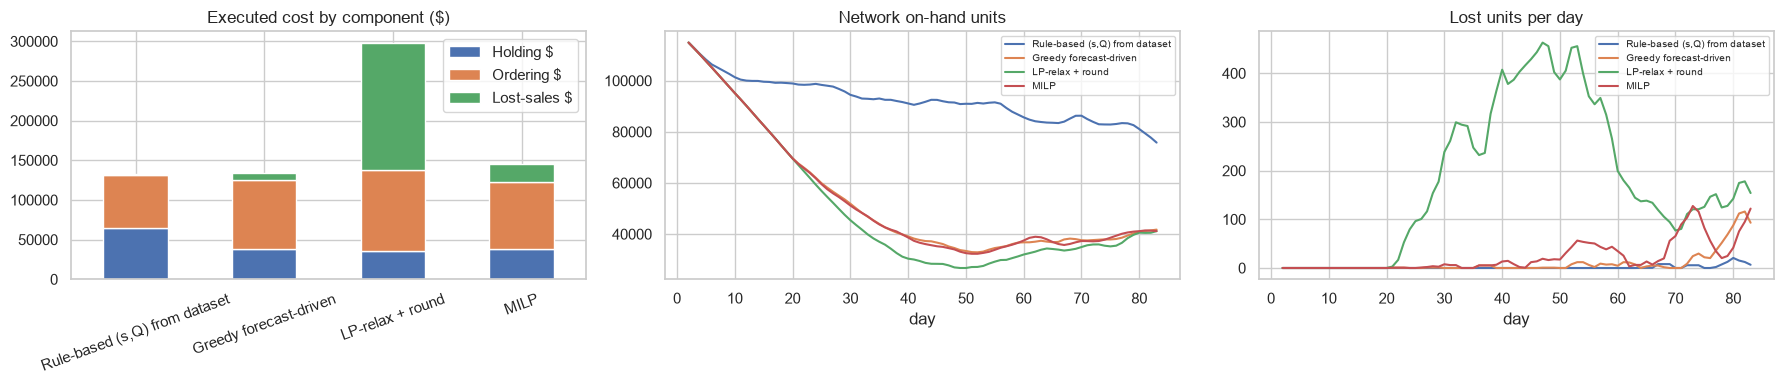

In [37]:
ref = 'Rule-based (s,Q) from dataset'
cmp_ = results[['Holding $', 'Ordering $', 'Lost-sales $', 'Total cost $', 'Fill rate %', 'Avg on-hand units', 'Constraint satisfaction %']].copy()
cmp_['Total cost vs rule-based %'] = 100 * (cmp_['Total cost $'] - cmp_.loc[ref, 'Total cost $']) / cmp_.loc[ref, 'Total cost $']
cmp_['Avg stock vs rule-based %'] = 100 * (cmp_['Avg on-hand units'] - cmp_.loc[ref, 'Avg on-hand units']) / cmp_.loc[ref, 'Avg on-hand units']
cmp_['Total cost vs greedy %'] = 100 * (cmp_['Total cost $'] - cmp_.loc['Greedy forecast-driven', 'Total cost $']) / cmp_.loc['Greedy forecast-driven', 'Total cost $']
display(cmp_.round(1))

print('Hard-constraint satisfaction on the executed plans (checks passed / total):')
cr = pd.concat({p: constraint_report(SIM[p]) for p in POLICIES}, axis=1)
display(cr.xs('rate %', axis=1, level=1).round(1))

gap = PLANS['MILP'][['block', 'lp_bound', 'cbc_bound', 'greedy_warm_start', 'milp_objective', 'gap_vs_cbc_bound_pct',
                     'gap_vs_lp_pct', 'improvement_vs_greedy_pct', 'runtime_s']].round(1)
display(gap)
print(f'Mean optimality gap: {gap.gap_vs_cbc_bound_pct.mean():.1f}% vs CBC best bound (tighter), '
      f'{gap.gap_vs_lp_pct.mean():.1f}% vs LP relaxation (looser). Median MILP-vs-greedy plan improvement {gap.improvement_vs_greedy_pct.median():.1f}%.')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
results[['Holding $', 'Ordering $', 'Lost-sales $']].plot.bar(stacked=True, ax=axes[0], title='Executed cost by component ($)')
axes[0].tick_params(axis='x', rotation=20)
for pol in POLICIES:
    pd.Series(SIM[pol]['inv'].sum(0)).rolling(3).mean().plot(ax=axes[1], label=pol)
axes[1].set_title('Network on-hand units'); axes[1].set_xlabel('day'); axes[1].legend(fontsize=7)
for pol in POLICIES:
    pd.Series(SIM[pol]['lost'].sum(0)).rolling(3).mean().plot(ax=axes[2], label=pol)
axes[2].set_title('Lost units per day'); axes[2].set_xlabel('day'); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

with mlflow.start_run(run_name='stage2_optimisation_rolling_eval'):
    mlflow.log_params({'horizon': H, 'replan_days': REPLAN, 'eval_days': EVAL_DAYS, 'solver': 'PuLP/CBC', 'milp_time_limit_s': MILP_TL,
                       'forecaster': BEST, 'moq': MOQ, 'max_order': MAXQ})
    for pol in POLICIES:
        mlflow.log_metrics(mlflow_clean({f'{pol} {k}': v for k, v in results.loc[pol].items()}))
    mlflow.log_metrics(mlflow_clean({'mean_gap_vs_cbc_bound_pct': gap.gap_vs_cbc_bound_pct.mean(),
                                     'mean_gap_vs_lp_pct': gap.gap_vs_lp_pct.mean(), 'mean_milp_runtime_s': gap.runtime_s.mean()}))
    results.to_csv(RESULTS_DIR / 'policy_comparison.csv'); gap.to_csv(RESULTS_DIR / 'milp_gaps.csv')
    mlflow.log_artifact(str(RESULTS_DIR / 'policy_comparison.csv')); mlflow.log_artifact(str(RESULTS_DIR / 'milp_gaps.csv'))


## 7. Solver runtime and scalability

Check how solution time and optimality change as the number of SKU-warehouse pairs increases.

,pairs,binaries,constraints,lp_s,milp_s,milp_obj,cbc_bound,gap_vs_cbc_bound_pct,gap_vs_lp_pct
0,25,481,2843,0.2,0.3,2142.5,2142.5,0.0,0.0
1,50,960,5247,0.3,2.0,4198.6,4198.6,0.0,4.0
2,125,2535,12606,0.4,20.3,10523.6,10226.5,2.8,5.7
3,250,5004,24546,0.8,21.4,21215.6,20808.5,1.9,4.5


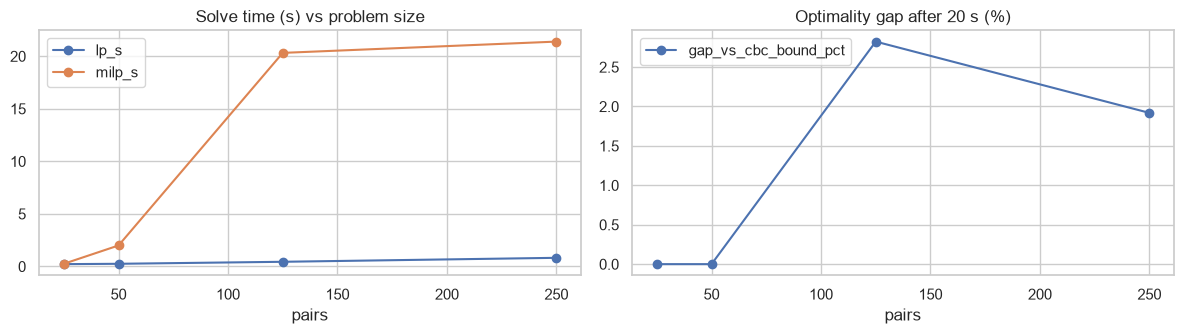

In [39]:
fp = FIRST_PLAN
rows_ = []
for n_pairs in [25, 50, 125, 250]:
    sel = np.linspace(0, N - 1, n_pairs).astype(int)
    lp = solve_plan(fp['F'], fp['inv'], fp['pipe'], mode='lp', prm=fp['prm'], sel=sel)
    mi = solve_plan(fp['F'], fp['inv'], fp['pipe'], mode='milp', prm=fp['prm'], sel=sel, time_limit=20)
    rows_.append(dict(pairs=n_pairs, binaries=mi['n_binaries'], constraints=mi['n_cons'], lp_s=lp['runtime'], milp_s=mi['runtime'],
                      milp_obj=mi['obj'], cbc_bound=mi['cbc_bound'], gap_vs_cbc_bound_pct=100 * (mi['obj'] - mi['cbc_bound']) / mi['obj'],
                      gap_vs_lp_pct=100 * (mi['obj'] - lp['obj']) / mi['obj']))
scale = pd.DataFrame(rows_)
display(scale.round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
scale.set_index('pairs')[['lp_s', 'milp_s']].plot(marker='o', ax=ax[0], title='Solve time (s) vs problem size')
scale.set_index('pairs')[['gap_vs_cbc_bound_pct']].plot(marker='o', ax=ax[1], title='Optimality gap after 20 s (%)')
plt.tight_layout(); plt.show()


## 8. Explainability

Review binding constraints, shadow prices, sensitivity results and one supplier disruption scenario.

In [38]:
D0 = 70
rec = SIM['MILP']
inv70 = rec['inv'][:, D0 - 1]
pipe70 = np.zeros((N, H))
for d_ in range(D0):                       # orders placed before day 70 that land on/after day 70
    arr_day = d_ + LEAD
    for p_ in np.where((rec['order'][:, d_] > 0) & (arr_day >= D0) & (arr_day - D0 < H))[0]:
        pipe70[p_, arr_day[p_] - D0] += rec['order'][p_, d_]
F70, prm70 = FC[D0], {**BASE, 'ss': compute_ss(FC[D0])}
base_lp = solve_plan(F70, inv70, pipe70, mode='lp', prm=prm70)
print(f'Day-{D0} plan: LP objective ${base_lp["obj"]:,.0f}, lost units {base_lp["lost"]:,.0f}, dock overflow {base_lp["dock_overflow"]:.0f}')

duals = pd.Series({n: c.pi for n, c in base_lp['model'].constraints.items() if n.startswith(('sup_', 'dock_', 'store_', 'ss_'))})
kind = duals.index.str.extract(r'^(sup|dock|store|ss)_(.*?)(?:_\d+)?(?:_\d+)?$')[0].to_numpy()
summary = pd.DataFrame({'type': kind, 'dual': duals.to_numpy()}, index=duals.index)
summary['binding'] = summary.dual.abs() > 1e-6
print(summary.groupby('type').agg(n=('dual', 'size'), binding=('binding', 'sum'), max_abs_dual=('dual', lambda s: s.abs().max())).round(3))

top = summary[summary.type.isin(['sup', 'dock', 'store'])].assign(a=lambda d: d.dual.abs()).sort_values('a', ascending=False).head(6)
display(top[['type', 'dual']].round(3))


Day-70 plan: LP objective $57,935, lost units 756, dock overflow 0
          n  binding  max_abs_dual
type                              
dock    140        5         1.645
ss     7000     5335         2.412
store   140        0         0.000
sup     258        3         0.905


,type,dual
dock_WH_3_3,dock,-1.645
sup_SUP_8_0,sup,-0.905
sup_SUP_4_0,sup,-0.670
sup_SUP_9_0,sup,-0.473
dock_WH_1_11,dock,-0.005
dock_WH_5_14,dock,-0.004


parameter,dock capacity x,fixed order cost x,lost-sale penalty x,supplier capacity x
value,,,,
0.50,NaN,50636.0,52641.0,NaN
0.60,41576927.0,NaN,NaN,61650.0
0.80,7562884.0,NaN,NaN,58682.0
1.00,57935.0,57935.0,57935.0,57935.0
1.25,57760.0,NaN,NaN,57664.0
1.50,57760.0,NaN,NaN,57625.0
2.00,NaN,72522.0,66687.0,NaN
4.00,NaN,101470.0,84189.0,NaN


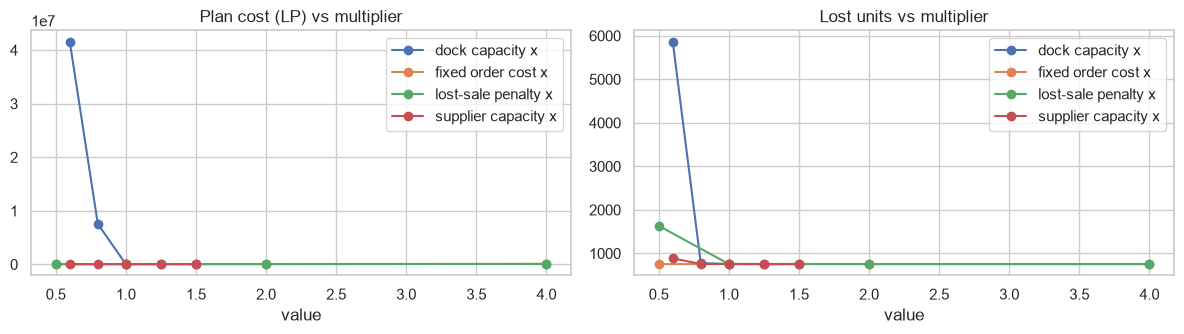

,Base plan,SUP_8 at 50% capacity,Change
Plan cost $,157634.0,186400.0,28766.0
Lost units,4419.0,6837.0,2418.0
Orders placed,381.0,368.0,-13.0
Units ordered from SUP_8,10071.0,4522.0,-5548.0
Units ordered from other suppliers,84299.0,86015.0,1716.0


What-if solved in 74s


In [40]:
def lp_lost_cost(prm_over=None, F=F70):
    prm = {**prm70, **(prm_over or {})}
    r = solve_plan(F, inv70, pipe70, mode='lp', prm=prm)
    return r['obj'], r['lost'], r['dock_overflow']


# Sensitivity 1: right-hand side - supplier dispatch capacity
rows_ = []
for f in [0.6, 0.8, 1.0, 1.25, 1.5]:
    o, l, e = lp_lost_cost({'sup_cap': {k: v * f for k, v in BASE['sup_cap'].items()}})
    rows_.append(dict(parameter='supplier capacity x', value=f, plan_cost=o, lost_units=l))
# Sensitivity 2: RHS - warehouse dock capacity
for f in [0.6, 0.8, 1.0, 1.25, 1.5]:
    o, l, e = lp_lost_cost({'dock_cap': {k: v * f for k, v in BASE['dock_cap'].items()}})
    rows_.append(dict(parameter='dock capacity x', value=f, plan_cost=o, lost_units=l))
# Sensitivity 3: objective coefficient - lost-sale penalty
for f in [0.5, 1.0, 2.0, 4.0]:
    o, l, e = lp_lost_cost({'pen': BASE['pen'] * f})
    rows_.append(dict(parameter='lost-sale penalty x', value=f, plan_cost=o, lost_units=l))
# Sensitivity 4: objective coefficient - fixed cost per order
for f in [0.5, 1.0, 2.0, 4.0]:
    o, l, e = lp_lost_cost({'K': BASE['K'] * f})
    rows_.append(dict(parameter='fixed order cost x', value=f, plan_cost=o, lost_units=l))
sens = pd.DataFrame(rows_)
display(sens.pivot(index='value', columns='parameter', values='plan_cost').round(0))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for par, g in sens.groupby('parameter'):
    g.plot(x='value', y='plan_cost', ax=axes[0], marker='o', label=par)
    g.plot(x='value', y='lost_units', ax=axes[1], marker='o', label=par)
axes[0].set_title('Plan cost (LP) vs multiplier'); axes[1].set_title('Lost units vs multiplier')
plt.tight_layout(); plt.show()

# What-if: supplier SUP_8 (largest binding supplier) loses 50% dispatch capacity for the whole plan, solved as MILP
disrupted = {**BASE['sup_cap'], 'SUP_8': BASE['sup_cap']['SUP_8'] * 0.5}
t0 = time.time()
ok = solve_milp(F70, inv70, pipe70, prm=prm70, time_limit=30)
bad = solve_milp(F70, inv70, pipe70, prm={**prm70, 'sup_cap': disrupted}, time_limit=30)
mask = (SUP_OF == 'SUP_8')
wi = pd.DataFrame({
    'Base plan': [ok['obj'], ok['lost'], ok['n_orders'], ok['Q'][mask].sum(), ok['Q'][~mask].sum()],
    'SUP_8 at 50% capacity': [bad['obj'], bad['lost'], bad['n_orders'], bad['Q'][mask].sum(), bad['Q'][~mask].sum()],
}, index=['Plan cost $', 'Lost units', 'Orders placed', 'Units ordered from SUP_8', 'Units ordered from other suppliers'])
wi['Change'] = wi.iloc[:, 1] - wi.iloc[:, 0]
display(wi.round(0))
print(f'What-if solved in {time.time() - t0:.0f}s')


### Results summary

The MILP reduces inventory substantially and respects capacity better, but its total cost is slightly higher than the existing rule under the assumed costs. The detailed tables above show the trade-off.

## 9. Limitations and next steps

The data is synthetic, stockouts are not recorded, and Q4 demand is difficult to forecast from one year of history. Costs and capacities should be replaced with real business values before deployment.